<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%209/MRayhanZamzami_JS09_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS 1 - Klasifikasi Jenis Suara dengan k-Nearest Neighbors (kNN)

Dataset: voice.csv (pengenalan gender male/female berdasarkan properti akustik suara).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset/voice.csv')
print('Ukuran dataset:', df.shape)
df.head()

Ukuran dataset: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [2]:
df.info()
print('\nDistribusi label:\n', df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

## 1. Analisis dan Pemilihan Fitur Optimal (Feature Selection)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_23108\2991040875.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_scores, x='F_Score', y='Fitur', palette='viridis')


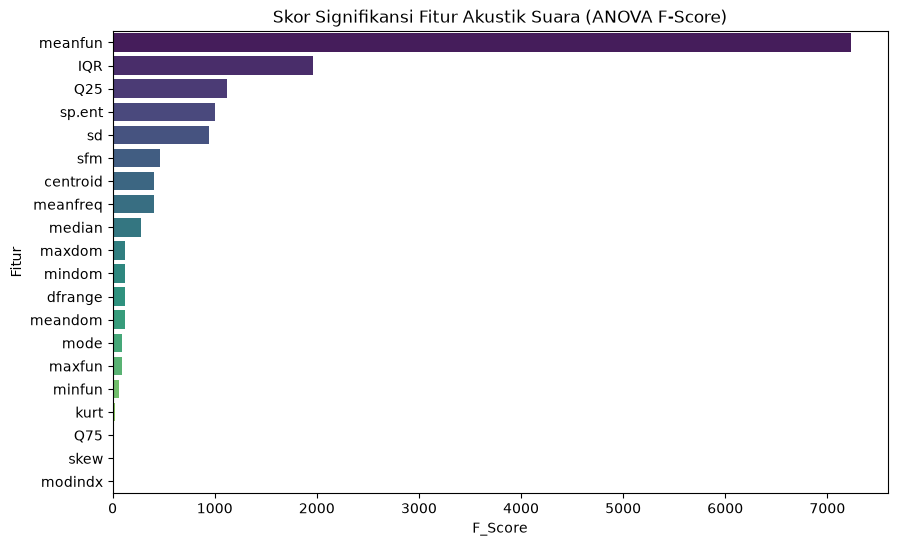

,Fitur,F_Score
0,meanfun,7228.790362
1,IQR,1965.750000
2,Q25,1121.569224
3,sp.ent,1003.308717
4,sd,945.461376
5,sfm,463.923194
6,centroid,406.752820
7,meanfreq,406.752820
8,median,277.588158
9,maxdom,126.024161


In [3]:
from sklearn.feature_selection import SelectKBest, f_classif

X_raw = df.iloc[:, :-1]
y_raw = df['label'].map({'male': 1, 'female': 0})

# Seleksi fitur menggunakan ANOVA F-test
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_raw, y_raw)

feat_scores = pd.DataFrame({
    'Fitur': X_raw.columns,
    'F_Score': selector.scores_
}).sort_values('F_Score', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_scores, x='F_Score', y='Fitur', palette='viridis')
plt.title('Skor Signifikansi Fitur Akustik Suara (ANOVA F-Score)')
plt.show()

display(feat_scores.head(10))

## 2. Eksperimen Jumlah Fitur Terbaik

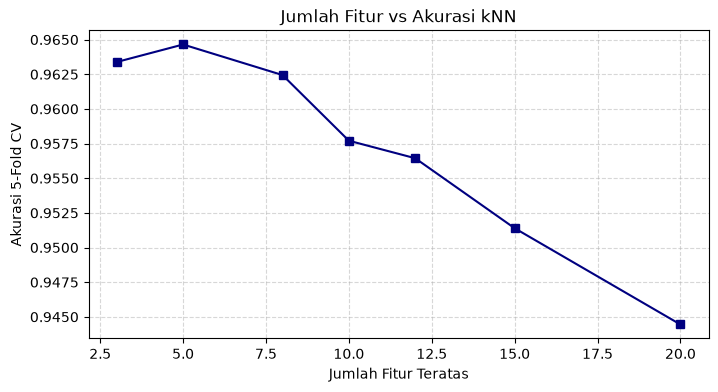

Fitur paling optimal (5 fitur):
['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd']


In [4]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

k_features_range = [3, 5, 8, 10, 12, 15, 20]
scores_by_feature_count = []

for num_f in k_features_range:
    top_cols = feat_scores['Fitur'].iloc[:num_f].values
    X_sub = StandardScaler().fit_transform(df[top_cols])
    knn = KNeighborsClassifier(n_neighbors=5)
    cv_score = cross_val_score(knn, X_sub, y_raw, cv=5, scoring='accuracy').mean()
    scores_by_feature_count.append(cv_score)

plt.figure(figsize=(8, 4))
plt.plot(k_features_range, scores_by_feature_count, marker='s', color='navy')
plt.xlabel('Jumlah Fitur Teratas')
plt.ylabel('Akurasi 5-Fold CV')
plt.title('Jumlah Fitur vs Akurasi kNN')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

best_n_feat = k_features_range[np.argmax(scores_by_feature_count)]
best_features = feat_scores['Fitur'].iloc[:best_n_feat].values
print(f'Fitur paling optimal ({best_n_feat} fitur):')
print(best_features.tolist())

## 3. Pencarian Nilai K Terbaik dengan Fitur Optimal

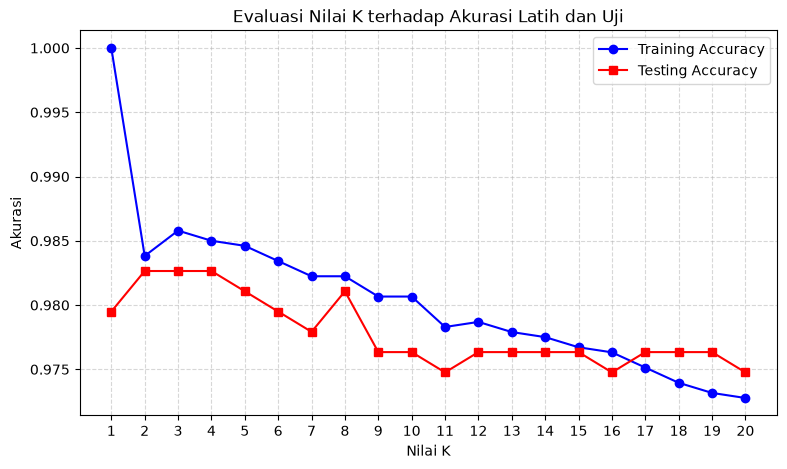

Nilai K terbaik: 2 dengan Akurasi Uji: 98.26%


In [5]:
from sklearn.model_selection import train_test_split

X_opt = df[best_features].values
X_train, X_test, y_train, y_test = train_test_split(
    X_opt, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

train_acc = []
test_acc = []
k_range = list(range(1, 21))

for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(k_range, train_acc, marker='o', label='Training Accuracy', color='blue')
plt.plot(k_range, test_acc, marker='s', label='Testing Accuracy', color='red')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.title('Evaluasi Nilai K terhadap Akurasi Latih dan Uji')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(k_range)
plt.show()

best_k = k_range[np.argmax(test_acc)]
print(f'Nilai K terbaik: {best_k} dengan Akurasi Uji: {max(test_acc)*100:.2f}%')

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train, y_train)
y_pred_final = final_knn.predict(X_test)

print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_final))
print('\nLaporan Klasifikasi Model Akhir:\n', classification_report(y_test, y_pred_final, target_names=['Female', 'Male']))

Confusion Matrix:
 [[312   5]
 [  6 311]]

Laporan Klasifikasi Model Akhir:
               precision    recall  f1-score   support

      Female       0.98      0.98      0.98       317
        Male       0.98      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634

